# 02 · Funnel and campaign analytics

> **All data in this notebook are synthetic** (fictional Indian retail brokerage, 10,000 users, Nov 2025 - Oct 2026, INR, snapshot 2026-10-31). No real company data are used.

All conversion metrics use the **mature cohort** (registered before 2026-10, n = 9,116) so every user had at least 31 days to progress.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fintech_analytics import config as C, loading, cleaning, eda, funnel, campaign, cohort, segmentation, support, kpi_report
%matplotlib inline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
d = loading.load_all(); users, act, tix, camp = d['users'], d['activity'], d['tickets'], d['campaigns']
print(f'users={len(users):,}  monthly rows={len(act):,}  tickets={len(tix):,}  campaigns={len(camp)}  (ALL DATA SYNTHETIC)')

users=10,000  monthly rows=64,645  tickets=7,614  campaigns=10  (ALL DATA SYNTHETIC)


## 1 · Onboarding funnel

In [2]:
ft = funnel.funnel_table(users); ft

,reached,pct_of_registered,step_conversion_pct,users_lost,share_of_all_losses_pct,conv_ci_low_pct,conv_ci_high_pct
Registered,9116,100.00,NaN,NaN,NaN,NaN,NaN
KYC Completed,6429,70.52,70.52,2687.0,42.60,69.58,71.45
Bank Linked,5645,61.92,87.81,784.0,12.43,86.98,88.58
First Deposit,4340,47.61,76.88,1305.0,20.69,75.76,77.96
First Trade,3462,37.98,79.77,878.0,13.92,78.55,80.94
Active (30d),2808,30.80,81.11,654.0,10.37,79.77,82.38


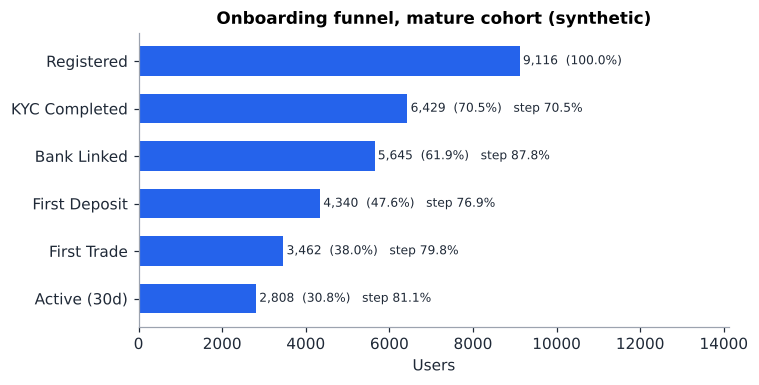

In [3]:
funnel.plot_funnel(users); plt.tight_layout(); plt.show()

**Reading it:** KYC is the largest leak in absolute terms (about 43% of all lost users), First Deposit is second. Step conversions and Wilson 95% intervals are in the table.

## 2 · Funnel by channel and device

In [4]:
funnel.funnel_by(users, 'acquisition_channel')

,acquisition_channel,mature_users,kyc,bank,deposit,trade,kyc_pct,bank_conv_pct,deposit_conv_pct,trade_conv_pct,reg_to_trade_pct
0,Referral,934,729,674,564,494,78.05,92.46,83.68,87.59,52.89
1,Organic,1722,1281,1192,981,812,74.39,93.05,82.30,82.77,47.15
2,Paid Search,2400,1726,1505,1127,878,71.92,87.20,74.88,77.91,36.58
3,CRM,512,347,296,222,174,67.77,85.30,75.00,78.38,33.98
4,Affiliate,692,469,409,303,233,67.77,87.21,74.08,76.90,33.67
5,Partnerships,533,343,304,221,166,64.35,88.63,72.70,75.11,31.14
6,Paid Social,2323,1534,1265,922,705,66.04,82.46,72.89,76.46,30.35


In [5]:
funnel.funnel_by(users, 'device_type')

,device_type,mature_users,kyc,bank,deposit,trade,kyc_pct,bank_conv_pct,deposit_conv_pct,trade_conv_pct,reg_to_trade_pct
0,iOS,2490,1823,1598,1246,989,73.21,87.66,77.97,79.37,39.72
1,Android,5503,3834,3387,2588,2070,69.67,88.34,76.41,79.98,37.62
2,Web,1123,772,660,506,403,68.74,85.49,76.67,79.64,35.89


## 3 · Time between stages (days, users who reached the stage)

In [6]:
funnel.time_to_stage(users)

,count,mean,50%,75%
KYC Completed,6429.0,5.9,6.0,9.0
Bank Linked,5645.0,4.0,4.0,6.0
First Deposit,4340.0,7.3,7.0,11.0
First Trade,3462.0,5.9,6.0,9.0


## 4 · Campaign scorecard
**CAC** = recorded spend / registered users. **Cost per first trader** = CAC / mature first-trade rate. Organic campaigns have no recorded spend, so CAC is undefined (NaN), not zero. No revenue or ROI is computed anywhere in this project.

In [7]:
sc = campaign.campaign_scorecard(users, camp)
sc[['campaign_id','campaign_name','channel','campaign_spend_inr','registered_users','cac_inr','first_trade_rate_mature_pct','cost_per_first_trader_inr','m3_retention_pct','rank_first_trade']]

,campaign_id,campaign_name,channel,campaign_spend_inr,registered_users,cac_inr,first_trade_rate_mature_pct,cost_per_first_trader_inr,m3_retention_pct,rank_first_trade
4,CMP05,Customer Referral,Referral,240000,1036,231.66,52.89,438.00,61.20,1
7,CMP08,Organic Social,Organic,0,704,NaN,48.15,NaN,58.64,2
6,CMP07,Organic Search,Organic,0,1174,NaN,46.55,NaN,61.38,3
1,CMP02,Generic Search,Paid Search,610000,1553,392.79,37.36,1051.40,54.44,4
0,CMP01,Brand Search,Paid Search,420000,1091,384.97,35.47,1085.41,54.70,5
9,CMP10,Email Nurture,CRM,90000,561,160.43,33.98,472.06,55.97,6
5,CMP06,Finance Affiliate,Affiliate,310000,757,409.51,33.67,1216.23,54.35,7
8,CMP09,Campus Events,Partnerships,190000,580,327.59,31.14,1051.83,50.77,8
3,CMP04,Video Awareness,Paid Social,450000,1168,385.27,30.78,1251.84,53.10,9
2,CMP03,Education Social,Paid Social,380000,1376,276.16,29.99,920.78,54.85,10


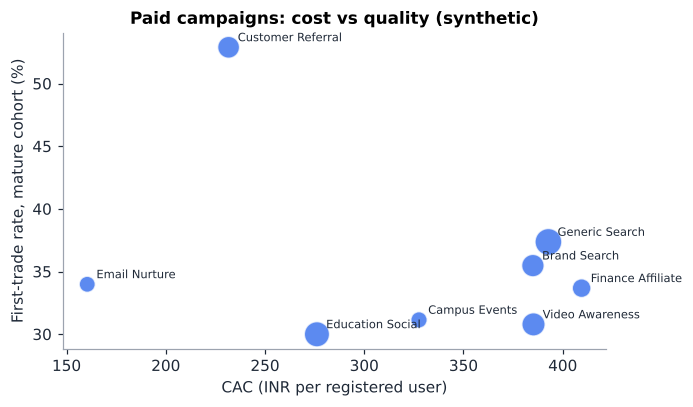

In [8]:
campaign.plot_cost_vs_quality(sc); plt.tight_layout(); plt.show()

Cheap registrations are not the same as cheap traders: Education Social has a moderate CAC but the lowest activation, so its cost per first trader is among the highest. Treat small gaps with caution - Phase 3 tested them statistically.

In [9]:
campaign.channel_scorecard(users)

,acquisition_channel,registrations,first_trade_pct,m3_retention_pct,dormant_3m_pct,tickets_per_1000_users
0,Referral,1036,52.9,61.2,15.5,718.1
1,Organic,1878,47.2,60.4,17.4,708.7
2,Paid Search,2644,36.6,54.6,23.4,775.3
3,CRM,561,34.0,56.0,22.0,771.8
4,Affiliate,757,33.7,54.4,25.2,797.9
5,Partnerships,580,31.1,50.8,23.8,824.1
6,Paid Social,2544,30.3,54.1,24.9,775.9
